In [29]:
import scanpy as sc 
import pandas as pd
import SEACells
import numpy as np
import matplotlib
from statistics import mode
import matplotlib.pyplot as plt
import seaborn as sns
import sys 
sys.path.insert(0, '../')
import utils
from importlib import reload
reload(utils)
from utils import *
# Some plotting aesthetics
%matplotlib inline

sns.set_style('ticks')
matplotlib.rcParams['figure.figsize'] = [4, 4]
matplotlib.rcParams['figure.dpi'] = 100


In [2]:
import scanpy as sc
adata = sc.read( r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_HVG5000.h5ad")
adata

AnnData object with n_obs × n_vars = 22608 × 5000
    obs: 'gRNA', 'n_gRNA', 'n_gRNA_UMIs', 'gene_target', 'celltype', 'perturbation_type', 'n_UMI_counts', 'n_genes', 'perturbed', 'channel', 'batch', 'perturbation', 'gene_target_ensembl_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier'
    var: 'gene_ids', 'feature_types', 'n_UMI_counts', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p'

In [3]:
ctrl_data = adata[adata.obs.perturbed == 'False'].copy()
ctrl_data

AnnData object with n_obs × n_vars = 1856 × 5000
    obs: 'gRNA', 'n_gRNA', 'n_gRNA_UMIs', 'gene_target', 'celltype', 'perturbation_type', 'n_UMI_counts', 'n_genes', 'perturbed', 'channel', 'batch', 'perturbation', 'gene_target_ensembl_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier'
    var: 'gene_ids', 'feature_types', 'n_UMI_counts', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p'

In [4]:
n_SEACells  = int(len(ctrl_data) / 50)
print(n_SEACells)
build_kernel_on = 'X_pca' # key in ad.obsm to use for computing metacells
                          # This would be replaced by 'X_svd' for ATAC data

## Additional parameters
n_waypoint_eigs = 10 # Number of eigenvalues to consider when initializing metacells
model = SEACells.core.SEACells(ctrl_data, 
                  build_kernel_on=build_kernel_on, 
                  n_SEACells=n_SEACells, 
                  n_waypoint_eigs=n_waypoint_eigs,
                  convergence_epsilon = 1e-5)

37
Welcome to SEACells!


In [5]:
import scanpy as sc

sc.pp.pca(
    ctrl_data,
    n_comps=50,
    random_state=0
)

print("PCA 结果形状：", ctrl_data.obsm["X_pca"].shape)

PCA 结果形状： (1856, 50)


In [6]:
model.construct_kernel_matrix()
M = model.kernel_matrix


Computing kNN graph using scanpy NN ...


  File "e:\Anaconda\envs\preprct\lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "e:\Anaconda\envs\preprct\lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
  File "e:\Anaconda\envs\preprct\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "e:\Anaconda\envs\preprct\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\Anaconda\envs\preprct\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


Computing radius for adaptive bandwidth kernel...


  0%|          | 0/1856 [00:00<?, ?it/s]

Making graph symmetric...
Parameter graph_construction = union being used to build KNN graph...
Computing RBF kernel...


  0%|          | 0/1856 [00:00<?, ?it/s]

Building similarity LIL matrix...


  0%|          | 0/1856 [00:00<?, ?it/s]

Constructing CSR matrix...


In [7]:
# Initialize archetypes
model.initialize_archetypes()

Building kernel on X_pca
Computing diffusion components from X_pca for waypoint initialization ... 
Done.
Sampling waypoints ...
Done.
Selecting 28 cells from waypoint initialization.
Initializing residual matrix using greedy column selection
Initializing f and g...


100%|██████████| 19/19 [00:00<00:00, 311.72it/s]

Selecting 9 cells from greedy initialization.


In [8]:
import scanpy as sc

# 1. 基于 PCA 构建邻居图
sc.pp.neighbors(ctrl_data, use_rep="X_pca")

# 2. 计算 UMAP
sc.tl.umap(ctrl_data, random_state=0)

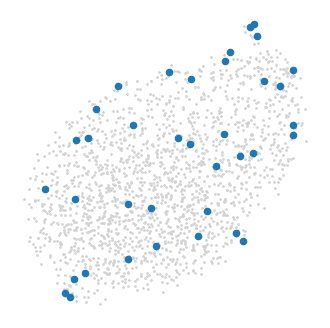

In [9]:
# Plot the initilization to ensure they are spread across phenotypic space
SEACells.plot.plot_initialization(ctrl_data, model)

In [10]:
model.fit(min_iter=10, max_iter=100)

Randomly initialized A matrix.
Setting convergence threshold at 0.00075
Starting iteration 1.
Completed iteration 1.
Starting iteration 10.
Completed iteration 10.
Starting iteration 20.
Completed iteration 20.
Starting iteration 30.
Completed iteration 30.
Starting iteration 40.
Completed iteration 40.
Starting iteration 50.
Completed iteration 50.
Converged after 52 iterations.


In [11]:
# You can force the model to run additional iterations step-wise using the .step() function
print(f'Ran for {len(model.RSS_iters)} iterations')
for _ in range(5):
    model.step()
print(f'Ran for {len(model.RSS_iters)} iterations')

Ran for 53 iterations
Ran for 58 iterations


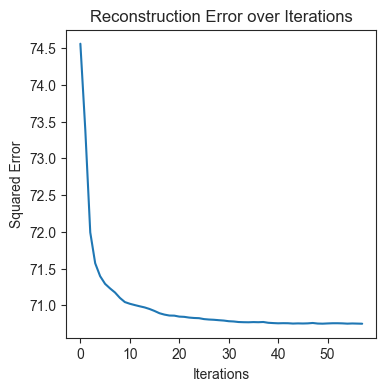

In [12]:
# Check for convergence 
model.plot_convergence()

In [13]:
ctrl_data.obs[['SEACell']].head()

,SEACell
index,
AAACCCACAGTAGGAC-1,SEACell-23
AAACGCTAGGTTGGTG-1,SEACell-23
AAACGCTTCTCTTGCG-1,SEACell-23
AAAGAACCAAAGGCAC-1,SEACell-36
AAAGGATTCGAGATGG-1,SEACell-23


In [14]:
adata.obs['SEACell'] = 'None'
adata.obs.loc[ctrl_data.obs.index.tolist(), 'SEACell'] = ctrl_data.obs['SEACell'].values

In [15]:
ctrl_data.layers['X'] = ctrl_data.X

In [16]:
import numpy as np
from scipy import sparse

X = ctrl_data.X

if sparse.issparse(X):
    values = X.data
else:
    values = np.asarray(X).ravel()

print("最小值：", values.min())
print("最大值：", values.max())
print("是否存在非整数值：", not np.allclose(values, np.round(values)))

最小值： 0.37292632
最大值： 5.6664267
是否存在非整数值： True


In [17]:
print("已有 layers：", list(ctrl_data.layers.keys()))
print("X shape：", ctrl_data.X.shape)
print("raw 是否存在：", ctrl_data.raw is not None)

已有 layers： ['X']
X shape： (1856, 5000)
raw 是否存在： False


In [18]:
# 按 SEACell 软分配权重汇总 ctrl_data.X
SEACell_soft_ad = SEACells.core.summarize_by_soft_SEACell(
    ctrl_data,
    model.A_,
    summarize_layer='X',
    minimum_weight=0.05
)

# 检查结果
print(SEACell_soft_ad)
print(SEACell_soft_ad.X.shape)
print(SEACell_soft_ad.obs.head())

100%|██████████| 37/37 [00:01<00:00, 27.54it/s]

AnnData object with n_obs × n_vars = 37 × 5000
    obs: 'Pseudo-sizes'
(37, 5000)
   Pseudo-sizes
0     32.744179
1     30.909111
2     41.179313
3     39.205977
4     40.774904


In [19]:
SEACell_soft_ad.obs

,Pseudo-sizes
0,32.744179
1,30.909111
2,41.179313
3,39.205977
4,40.774904
5,48.890606
6,52.307533
7,32.801435
8,62.846587
9,51.578042


In [20]:
print("SEACell_soft_ad:", SEACell_soft_ad)
print("表达矩阵形状:", SEACell_soft_ad.shape)
print("obs 列:", SEACell_soft_ad.obs.columns.tolist())
print("var 列:", SEACell_soft_ad.var.columns.tolist())
print("是否有 cell_type:", "cell_type" in SEACell_soft_ad.obs.columns)
print("基因名示例:", SEACell_soft_ad.var_names[:5].tolist())

SEACell_soft_ad: AnnData object with n_obs × n_vars = 37 × 5000
    obs: 'Pseudo-sizes'
表达矩阵形状: (37, 5000)
obs 列: ['Pseudo-sizes']
var 列: []
是否有 cell_type: False
基因名示例: ['MIR1302-2HG', 'LINC02593', 'ENSG00000224969', 'TNFRSF18', 'INTS11']


In [21]:
# 将 var_names 中的基因名补到 gene_name 列
SEACell_soft_ad.var["gene_name"] = (
    SEACell_soft_ad.var_names.astype(str)
)

# 补上统一的细胞类型标签
SEACell_soft_ad.obs["cell_type"] = "KOLF"

# 检查
print(SEACell_soft_ad.var["gene_name"].head())
print(SEACell_soft_ad.obs["cell_type"].unique())

MIR1302-2HG            MIR1302-2HG
LINC02593                LINC02593
ENSG00000224969    ENSG00000224969
TNFRSF18                  TNFRSF18
INTS11                      INTS11
Name: gene_name, dtype: object
['KOLF']


In [22]:
import os
import numpy as np
import torch

path = r"E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main\graphs\KOLF"
os.makedirs(path, exist_ok=True)

cell_type = "KOLF"

cell = Correlation_matrix(
    SEACell_soft_ad,
    cell_type,
    "cell_type",
    hv_genes_cells=None,
    union_HVGs=True
)

threshold = np.percentile(
    np.abs(cell[0].values),
    99.0
)

print("相关性矩阵形状:", cell[0].shape)
print("threshold:", threshold)

g = create_coexpression_graph(
    SEACell_soft_ad,
    cell,
    cell_type,
    threshold,
    "gene_name"
)

print("节点数:", g.num_nodes)
print("边数:", g.num_edges)

g.pos = torch.as_tensor(g.pos, dtype=torch.float32)

save_path = os.path.join(path, "KOLF_A_4w_coexpr_graph.pkl")
torch.save(g, save_path)

print("图已保存:", save_path)

e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\Anaconda\envs\preprct\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


相关性矩阵形状: (25000000,)
threshold: 0.6133493210015447
number_of_edges before the threshold (5000 x 5000):  25000000
number_of_edges after the threshold:  250001
number_of_edges after removing self loops:  246234
final number_of_edges:  246234
节点数: 3594
边数: 246234
图已保存: E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main\graphs\KOLF\KOLF_A_4w_coexpr_graph.pkl


In [23]:
celltype_counts = adata.obs["celltype"].value_counts(dropna=False)
print(celltype_counts.to_string())

celltype
KRAB-ZIM3-dCas9 KOLF2.1J hiPSC    22608


In [24]:
# 统一字段名，适配 PrePR-CT
adata.obs["cell_type"] = adata.obs["celltype"].astype(str)

adata.obs["condition"] = "control"
adata.obs.loc[
    adata.obs["perturbed"].astype(str) == "True",
    "condition"
] = adata.obs.loc[
    adata.obs["perturbed"].astype(str) == "True",
    "gene_target"
].astype(str)

adata.obs["cov_drug"] = (
    adata.obs["cell_type"] + "_" + adata.obs["condition"]
)

# 划分对照和扰动细胞
ctrl_data = adata[
    adata.obs["perturbed"].astype(str) == "False"
].copy()

stim_data = adata[
    adata.obs["perturbed"].astype(str) == "True"
].copy()

print("Control:", ctrl_data.n_obs)
print("Perturbation:", stim_data.n_obs)
print("扰动靶基因数:", stim_data.obs["gene_target"].nunique())

Control: 1856
Perturbation: 20752
扰动靶基因数: 3542


In [25]:
# 查看当前 adata 中保存的 SEACell 标签
print("adata 是否有 SEACell：", "SEACell" in adata.obs.columns)

# 查看已有的相关列
print([
    c for c in adata.obs.columns
    if "seacell" in c.lower() or "cell" in c.lower()
])

adata 是否有 SEACell： True
['celltype', 'SEACell', 'cell_type']


In [27]:
import os
import pickle

full_data_path = r"E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main\Data_Notebooks\\"
graphs_data = "KOLF"

print("数据文件路径：", os.path.join(full_data_path, f"cells_{graphs_data}.pkl"))

数据文件路径： E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main\Data_Notebooks\\cells_KOLF.pkl


In [33]:
import os
import pickle
import numpy as np
import torch
from importlib import reload
import utils
from tqdm.auto import tqdm

# ============================================================
# 1. 恢复已保存的 KOLF 图
# ============================================================
graph_path = (
    r"E:\VSCODE\PrePR-CT\Cell-Type-Specific-Graphs-main"
    r"\graphs\KOLF\KOLF_A_4w_coexpr_graph.pkl"
)

graph = torch.load(
    graph_path,
    map_location="cpu",
    weights_only=False
)

# pos 是基因节点对应的索引，必须为整数
graph.pos = torch.as_tensor(graph.pos, dtype=torch.long)

# KOLF 只有一张图
cell_type_network = {"KOLF": graph}

print("已加载 KOLF 图，节点数：", graph.num_nodes)

# ============================================================
# 2. 沿用原版字段和分组方式
# ============================================================
adata.obs["cell_type"] = "KOLF"

adata.obs["condition"] = "control"
mask_stim = adata.obs["perturbed"].astype(str).to_numpy() == "True"

adata.obs.loc[mask_stim, "condition"] = (
    adata.obs.loc[mask_stim, "gene_target"].astype(str)
)

adata.obs["cov_drug"] = (
    adata.obs["cell_type"].astype(str)
    + "_"
    + adata.obs["condition"].astype(str)
)

ctrl_data = adata[
    adata.obs["condition"] == "control"
].copy()

stim_data = adata[
    adata.obs["condition"] != "control"
].copy()

# ============================================================
# 3. 按原版流程更新图的 control 均值和方差特征
# ============================================================
genes = graph.pos.tolist()
ctrl_expr = ctrl_data[:, genes].X

if hasattr(ctrl_expr, "toarray"):
    ctrl_expr = ctrl_expr.toarray()

ctrl_tensor = torch.as_tensor(
    np.asarray(ctrl_expr),
    dtype=torch.float32
)

graph.x = torch.stack(
    [
        ctrl_tensor.mean(dim=0),
        ctrl_tensor.var(dim=0, unbiased=False)
    ],
    dim=1
)

# ============================================================
# 4. 按 Kang 原版 cell 38 的逻辑匹配 control
# ============================================================
# 原版把匹配后的 control 表达存进 ctrl_x。
# 使用 float32，避免默认 float64 带来的内存开销。
stim_data.layers["ctrl_x"] = np.zeros(
    stim_data.shape,
    dtype=np.float32
)

for cov_drug in tqdm(
    stim_data.obs["cov_drug"].unique(),
    desc="Matching control cells"
):
    ad_stim = stim_data[
        stim_data.obs["cov_drug"] == cov_drug
    ]

    num_samples = ad_stim.n_obs

    # 只有一张 KOLF 图，所以所有扰动都匹配同一批 control
    sele_samples = balance_subsample(
        np.asarray(ctrl_data.obs_names),
        np.asarray(ctrl_data.obs["SEACell"]),
        num_samples
    )

    matched = ctrl_data[sele_samples, :].X

    if hasattr(matched, "toarray"):
        matched = matched.toarray()

    row_idx = stim_data.obs_names.get_indexer(
        ad_stim.obs_names
    )

    stim_data.layers["ctrl_x"][row_idx, :] = np.asarray(
        matched,
        dtype=np.float32
    )

print("Control 匹配完成。")

# ============================================================
# 5. 调用原版 create_cells
# ============================================================
reload(utils)
from utils import *

cells_train = create_cells(
    stim_data,
    cell_type_network,
    None
)

print("训练样本数：", len(cells_train))

# ============================================================
# 6. 保存训练样本
# ============================================================
output_path = os.path.join(
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc",
    "cells_KOLF.pkl"
)

with open(output_path, "wb") as f:
    pickle.dump(cells_train, f)

print("已保存：", output_path)

已加载 KOLF 图，节点数： 3594


Matching control cells:   0%|          | 0/3542 [00:00<?, ?it/s]

Control 匹配完成。
['KOLF'] ['ZNF446' 'ZNF572' 'SIRT3' ... 'ABRAXAS1' 'SOX11' 'EIF4A3']


Processing cov_drugs:   0%|          | 0/3542 [00:00<?, ?it/s]

Processing KOLF_ZNF446 samples:   0%|          | 0/4 [00:00<?, ?it/s]

...

Processing KOLF_ZNF568 samples:   0%|          | 0/1 [00:00<?, ?it/s]

Processing KOLF_ABRAXAS1 samples:   0%|          | 0/1 [00:00<?, ?it/s]

Processing KOLF_SOX11 samples:   0%|          | 0/1 [00:00<?, ?it/s]

Processing KOLF_EIF4A3 samples:   0%|          | 0/1 [00:00<?, ?it/s]

训练样本数： 20752
已保存： E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\cells_KOLF.pkl


NameError: name 'cells_train' is not defined